Install libraries

In [ ]:
%pip install pandas numpy scikit-learn matplotlib

   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   -------- ------------------------------- 2.4/11.0 MB 12.2 MB/s eta 0:00:01
   ----------------- ---------------------- 4.7/11.0 MB 11.4 MB/s eta 0:00:01
   ------------------------- -------------- 7.1/11.0 MB 11.5 MB/s eta 0:00:01
   ---------------------------------- ----- 9.4/11.0 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 11.0/11.0 MB 10.7 MB/s  0:00:01
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ------- -------------------------------- 2.4/12.6 MB 11.2 MB/s eta 0:00:01
   -------------- ------------------------- 4.5/12.6 MB 10.7 MB/s eta 0:00:01
   --------------------- ------------------ 6.8/12.6 MB 11.0 MB/s eta 0:00:01
   ----------------------------- ---------- 9.2/12.6 MB 11.2 MB/s eta 0:00:01
   ------------------------------------ --- 11.5/12.6 MB 11.4 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 10.7 MB/s  0:00:01
   --

In [1]:
import pandas as pd
import numpy as np
from sklearn import linear_model
import matplotlib.pyplot as plt

In [9]:
df = pd.read_csv('../datasets/data_lr.csv')
jeolee_data = df.head(3)
print(jeolee_data)

   area   price
0  2600  550000
1  3000  565000
2  3200  610000


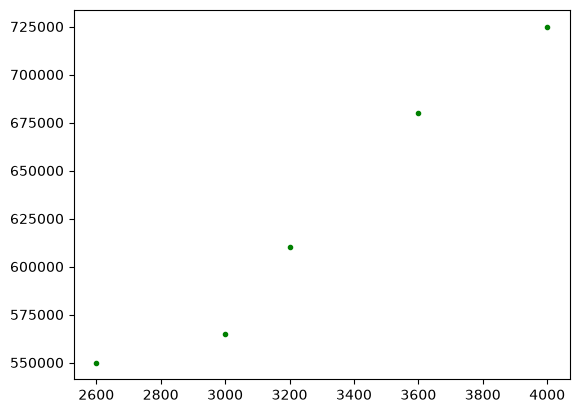

In [ ]:
%matplotlib inline
#plt.xlabel('area')
#plt.ylabel('price')
x_ax = df.area
y_ax = df.price
plt.scatter(x_ax,y_ax, color='green',marker='.')

In [20]:
aldub_df = df.drop('price',axis='columns')
aldub_df

,area
0,2600
1,3000
2,3200
3,3600
4,4000


In [22]:
kathniel_df = df.price
kathniel_df

0    550000
1    565000
2    610000
3    680000
4    725000
Name: price, dtype: int64

In [ ]:
# Create a linear regression model
reg = linear_model.LinearRegression()
reg.fit(aldub_df, kathniel_df)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[135.79]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['area']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.806e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [25]:
reg.predict([[6900]])

c:\Users\RoblesKeithYves\Desktop\ML_Elec\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([1117551.36986301])

In [29]:
m =reg.coef_

In [30]:
b = reg.intercept_

In [33]:
y_value = m * 6900 + b
y_value

array([1117551.36986301])

generate predictions

In [42]:
jadine = pd.read_csv('../datasets/areas.csv')
jadine

,area
0,2750
1,3120
2,2890
3,3450
4,3780
5,2640
6,3320
7,3950
8,3610
9,2980


In [43]:
pred = reg.predict(jadine)
pred

array([554032.53424658, 604273.97260274, 573042.80821918, 649083.90410959,
       693893.83561644, 539095.89041096, 631431.50684932, 716977.73972603,
       670809.93150685, 585263.69863014])

In [44]:
jadine['prices']=pred
jadine

,area,prices
0,2750,554032.534247
1,3120,604273.972603
2,2890,573042.808219
3,3450,649083.904110
4,3780,693893.835616
5,2640,539095.890411
6,3320,631431.506849
7,3950,716977.739726
8,3610,670809.931507
9,2980,585263.698630


In [45]:
jadine.to_csv("predictions.csv")